**Large Language Models**

_Copyright Notice_

This notebook is available for educational purposes. You may not use or distribute this notebook for commercial purposes. You may make copies of this notebook and use or distribute it for educational purposes as long as you cite the author as the source of the notebook.

Jaeyoung Chun | School of Applied Artificial Intelligence | Handong Global University

# State 1

## State

In [1]:
from typing_extensions import TypedDict

In [2]:
class State(TypedDict):
    aggregate: list

## Node

In [3]:
def node_a(state: State):
    return {"aggregate": ["data 1"]}


def node_b(state: State):
    return {"aggregate": ["data 2"]}


def node_c(state: State):
    return {"aggregate": ["data 3"]}


def node_d(state: State):
    return {"aggregate": ["data 4"]}

## Build Graph

In [4]:
from langgraph.graph import StateGraph, START, END

In [5]:
graph = (
    StateGraph(State)
        
    # node
    .add_node("a", node_a)
    .add_node("b", node_b)
    .add_node("c", node_c)
    .add_node("d", node_d)
        
    # edge
    .add_edge(START, "a")
    .add_edge("a", "b")
    .add_edge("b", "c")
    .add_edge("c", "d")
    .add_edge("d", END)
        
    # compile
    .compile()
)

## Visualize Graph

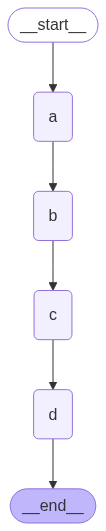

In [6]:
from IPython.display import Image, display

diagram = Image(graph.get_graph().draw_mermaid_png())
    
display(diagram)

## Run

Expected `['data 1', 'data 2', 'data 3', 'data 4']`, but...

In [7]:
out = graph.invoke(
    {
        "aggregate": []
    }
)

In [8]:
out

{'aggregate': ['data 4']}